# Bằng chứng thực nghiệm: so sánh DAS3H với các mô hình đối chứng trên EdNet

Notebook này dùng để **kiểm chứng và tái lập** các số liệu trong Hình 4.3 (Bảng 4.6, 4.7) của khóa luận:

| Mô hình | AUC | Log loss | Brier | Nguồn kết quả gốc |
|---|---|---|---|---|
| DAS3H d=0 (đang triển khai) | 0,7037 | 0,5797 | 0,1979 | `das3h-production/artifacts/own-20261019/training-report.json` (19/10/2026) |
| Log-PFA + item | 0,7023 | 0,5774 | 0,1971 | `kt-benchmark/results/serving-aligned-scaled-seed42/report.json` |
| Item-only | 0,6988 | 0,5890 | 0,2018 | `das3h-production/.../training-report.json` |
| DKT (pyKT) | 0,6083 | 0,6211 | 0,2154 | `kt-benchmark/artifacts/seed42/dkt-report.json` (22/10/2026) |
| BKT (pyBKT) | 0,5952 | 0,6236 | 0,2166 | `kt-benchmark/artifacts/seed42/bkt-report.json` (22/10/2026) |

Notebook làm bốn việc:

1. **Kiểm tra dữ liệu**: mã băm SHA-256 của tệp tương tác, danh mục câu hỏi và bộ nhãn OWN trùng với mã băm ghi trong các báo cáo gốc; chia tập theo người học đúng 70/15/15.
2. **Chấm lại từ mô hình đã lưu**: nạp đúng tham số DAS3H, BKT và checkpoint DKT đã chọn khi huấn luyện, dự đoán lại trên tập kiểm thử và so với số đã báo cáo.
3. **Huấn luyện lại từ đầu** các mô hình hồi quy logistic (DAS3H d=0, Item-only, Log-PFA + item) bằng đúng mã nguồn và lưới siêu tham số gốc, chọn theo tập validation, rồi mới chấm trên tập test.
4. **Vẽ lại Hình 4.3** từ các số vừa tính.

BKT và DKT không được huấn luyện lại trong notebook vì mất nhiều thời gian (khoảng 19 phút và 9 phút trên CPU ở lượt chạy gốc); thay vào đó notebook nạp lại đúng tham số/checkpoint đã chọn bằng validation và hiển thị nhật ký huấn luyện đã lưu.

**Cách chạy lại:** mở notebook trong thư mục `experiments/kt-benchmark`, môi trường Python 3.12 với các phiên bản trong `requirements.txt` (numpy 1.26.4, scipy 1.14.1, scikit-learn 1.5.2, pandas 2.2.3) và PyTorch; chọn *Run All*. Toàn bộ mất khoảng 10–15 phút trên CPU.

In [1]:
import json, platform, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, torch
import matplotlib, matplotlib.pyplot as plt

HERE = Path.cwd()
assert (HERE / 'common.py').exists(), 'Hãy mở notebook trong thư mục experiments/kt-benchmark'
from common import ROOT, load_cohort, learner_splits, metrics, sha
sys.path.insert(0, str(ROOT / 'ednet_santa_mapping_clean'))

T0 = time.time()
print('Thời điểm chạy :', time.strftime('%d/%m/%Y %H:%M:%S'))
print('Python         :', platform.python_version(), '|', platform.system())
print('numpy', np.__version__, '| scipy', scipy.__version__, '| scikit-learn', sklearn.__version__,
      '| pandas', pd.__version__, '| torch', torch.__version__)

Thời điểm chạy : 24/11/2026 13:35:43
Python         : 3.12.3 | Linux
numpy 1.26.4 | scipy 1.14.1 | scikit-learn 1.5.2 | pandas 2.2.3 | torch 2.5.1+cu124


## 1. Dữ liệu và cách chia tập

Dữ liệu là nhóm 3.000 người học được lấy từ EdNet KT4 (tệp `u3000_e0_s2026.csv.gz`), mỗi dòng là một lượt trả lời đã nộp. Câu hỏi được gắn nhãn kỹ năng OWN (mục 4.1.2). Hàm `load_cohort()` tự kiểm tra số dòng, số người học và mã băm danh mục câu hỏi với manifest trước khi trả dữ liệu.

In [2]:
df, tags, hashes = load_cohort()
art_dir = HERE / 'artifacts/seed42'
das3h_dir = ROOT / 'experiments/das3h-production/artifacts/own-20261019'
reports = {
    'das3h_training': json.loads((das3h_dir / 'training-report.json').read_text(encoding='utf-8')),
    'bkt': json.loads((art_dir / 'bkt-report.json').read_text(encoding='utf-8')),
    'dkt': json.loads((art_dir / 'dkt-report.json').read_text(encoding='utf-8')),
    'logistic': json.loads((HERE / 'results/serving-aligned-scaled-seed42/report.json').read_text(encoding='utf-8')),
}
rows = []
for key in ['cohort', 'catalog', 'projection']:
    rows.append({'Tệp': key, 'SHA-256 hiện tại (16 ký tự đầu)': hashes[key][:16],
                 'Khớp DAS3H': reports['das3h_training']['sourceHashes'][key] == hashes[key],
                 'Khớp BKT': reports['bkt']['sourceHashes'][key] == hashes[key],
                 'Khớp DKT': reports['dkt']['sourceHashes'][key] == hashes[key],
                 'Khớp Log-PFA': reports['logistic']['sourceHashes'][key] == hashes[key]})
hash_table = pd.DataFrame(rows)
display(hash_table)
assert hash_table.drop(columns=['Tệp', 'SHA-256 hiện tại (16 ký tự đầu)']).all().all(), 'Dữ liệu khác với lúc huấn luyện'
print('Số lượt trả lời:', f'{len(df):,}', '| Số người học:', df.user_id.nunique(), '| Số câu hỏi:', df.question_id.nunique())

,Tệp,SHA-256 hiện tại (16 ký tự đầu),Khớp DAS3H,Khớp BKT,Khớp DKT,Khớp Log-PFA
0,cohort,5b72a4df9bb14f0b,True,True,True,True
1,catalog,137d2936b746c98e,True,True,True,True
2,projection,d19ecbf41c79ee18,True,True,True,True


Số lượt trả lời: 413,744 | Số người học: 3000 | Số câu hỏi: 11544


In [3]:
splits = learner_splits(df, 42)
masks = {k: df.user_id.isin(v).to_numpy() for k, v in splits.items()}
split_table = pd.DataFrame({k: {'Người học': len(splits[k]), 'Lượt trả lời': int(masks[k].sum())} for k in ['train', 'val', 'test']}).T
display(split_table)
assert not (splits['train'] & splits['val'] or splits['train'] & splits['test'] or splits['val'] & splits['test']), 'Trùng người học giữa các tập'
for k in ['train', 'val', 'test']:
    assert split_table.loc[k, 'Lượt trả lời'] == reports['dkt']['counts'][k]['events'] == reports['das3h_training']['counts'][k]['events']
print('Không có người học nào xuất hiện ở hai tập; số lượt mỗi tập trùng với báo cáo gốc.')
test = df[masks['test']]
y = df.correct.to_numpy()

,Người học,Lượt trả lời
train,2100,281250
val,450,66647
test,450,65847


Không có người học nào xuất hiện ở hai tập; số lượt mỗi tập trùng với báo cáo gốc.


## 2. Chấm lại DAS3H d=0 từ mô hình đang triển khai

`model.json` là tham số DAS3H mà hệ thống đang dùng. Hàm `predict_das3h` tính lại xác suất từng lượt trên tập test, chỉ dùng lịch sử **trước** thời điểm nộp (các câu cùng lượt nộp không nhìn thấy đáp án của nhau).

In [4]:
from compare import predict_das3h, paired_loss_interval
artifact = json.loads((das3h_dir / 'model.json').read_text(encoding='utf-8'))
t = time.time()
p_das3h = predict_das3h(test, artifact)
m_das3h_reload = metrics(test.correct, p_das3h)
reported = reports['das3h_training']['metrics']['own_das3h']
display(pd.DataFrame({'Báo cáo gốc': {k: reported[k] for k in ['auc', 'log_loss', 'brier', 'accuracy']},
                      'Chấm lại': {k: m_das3h_reload[k] for k in ['auc', 'log_loss', 'brier', 'accuracy']}}))
print(f'Chênh lệch lớn nhất: {max(abs(m_das3h_reload[k] - reported[k]) for k in ["auc", "log_loss", "brier", "accuracy"]):.2e}  ({time.time() - t:.0f} giây)')

,Báo cáo gốc,Chấm lại
auc,0.703701,0.703701
log_loss,0.579725,0.579725
brier,0.197895,0.197895
accuracy,0.695339,0.695339


Chênh lệch lớn nhất: 5.19e-10  (42 giây)


## 3. Huấn luyện lại DAS3H d=0 và Item-only từ đầu

Theo đúng `experiments/das3h-production/train.py`: hồi quy logistic (liblinear, L2), thử C ∈ {0,1; 1; 10}, **chọn C theo log loss trên tập validation**, sau đó mới chấm một lần trên tập test. Item-only dùng cùng mã hóa nhưng bỏ toàn bộ đặc trưng kỹ năng (chỉ còn độ khó câu hỏi và hệ số người học).

In [5]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from src.das3h_comparison import encode_history

projection = json.loads((ROOT / 'ednet_santa_mapping_clean/outputs/ednet_with_own_tags.json').read_text(encoding='utf-8'))
skills = {r['question_id']: sorted(set(r['own_content_tag_ids'])) for r in projection}
raw = pd.read_csv(ROOT / 'ednet_santa_mapping_clean/data/interaction_cache/u3000_e0_s2026.csv.gz', dtype={'user_id': str})
from src.das3h_test import split_users
raw_splits = split_users(raw, 42)
raw_masks = {k: raw.user_id.isin(v).to_numpy() for k, v in raw_splits.items()}
y_raw = raw.correct.to_numpy()

def fit_grid(X, yv, m, grid, name, scale=None):
    trials, best = [], None
    tr, va = X[m['train']], X[m['val']]
    if scale is not None:
        tr, va = tr.multiply(scale).tocsr(), va.multiply(scale).tocsr()
    for c in grid:
        model = LogisticRegression(C=c, solver='liblinear', max_iter=1000, tol=1e-5, random_state=42)
        with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(tr, yv[m['train']])
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        loss = metrics(yv[m['val']], model.predict_proba(va)[:, 1])['log_loss']
        trials.append({'Mô hình': name, 'C': c, 'Log loss validation': loss, 'Hội tụ': converged})
        if converged and (best is None or (loss, c) < (best[0], best[1])):
            best = (loss, c, model)
    return trials, best

retrained, all_trials = {}, []
for name, tagmap in [('Item-only', {q: [] for q in skills}), ('DAS3H d=0', skills)]:
    t = time.time()
    X = encode_history(raw, tagmap, raw_splits['train'])
    trials, (vloss, c, model) = fit_grid(X, y_raw, raw_masks, [.1, 1., 10.], name)
    all_trials += trials
    retrained[name] = {**metrics(y_raw[raw_masks['test']], model.predict_proba(X[raw_masks['test']])[:, 1]), 'C chọn': c}
    print(f'{name}: chọn C={c} theo validation, {X.shape[1]:,} đặc trưng, {time.time() - t:.0f} giây')
    del X
display(pd.DataFrame(all_trials))

Item-only: chọn C=1.0 theo validation, 15,269 đặc trưng, 4 giây


DAS3H d=0: chọn C=1.0 theo validation, 16,281 đặc trưng, 197 giây


,Mô hình,C,Log loss validation,Hội tụ
0,Item-only,0.1,0.602561,True
1,Item-only,1.0,0.599904,True
2,Item-only,10.0,0.615071,True
3,DAS3H d=0,0.1,0.586358,True
4,DAS3H d=0,1.0,0.584556,True
5,DAS3H d=0,10.0,0.599235,True


In [6]:
orig_trials = pd.DataFrame(reports['das3h_training']['trials']).rename(columns={'variant': 'Mô hình', 'validationLogLoss': 'Log loss validation (gốc)'})
orig_trials['Mô hình'] = orig_trials['Mô hình'].map({'item_only': 'Item-only', 'own_das3h': 'DAS3H d=0'})
cmp_trials = pd.DataFrame(all_trials).merge(orig_trials[['Mô hình', 'C', 'Log loss validation (gốc)']], on=['Mô hình', 'C'])
cmp_trials['Chênh lệch'] = (cmp_trials['Log loss validation'] - cmp_trials['Log loss validation (gốc)']).abs()
display(cmp_trials)
print('Cả hai lần chạy đều chọn cùng giá trị C cho mỗi mô hình:',
      all(reports['das3h_training']['metrics'][k]['C'] == retrained[v]['C chọn'] for k, v in [('item_only', 'Item-only'), ('own_das3h', 'DAS3H d=0')]))

,Mô hình,C,Log loss validation,Hội tụ,Log loss validation (gốc),Chênh lệch
0,Item-only,0.1,0.602561,True,0.602561,6.574144e-08
1,Item-only,1.0,0.599904,True,0.599904,4.559987e-09
2,Item-only,10.0,0.615071,True,0.615071,3.328786e-07
3,DAS3H d=0,0.1,0.586358,True,0.586358,9.914830e-08
4,DAS3H d=0,1.0,0.584556,True,0.584557,6.515122e-07
5,DAS3H d=0,10.0,0.599235,True,0.599236,9.358155e-07


Cả hai lần chạy đều chọn cùng giá trị C cho mỗi mô hình: True


## 4. Huấn luyện lại Log-PFA + item

Theo `run_serving_aligned.py`: cùng bộ mã hóa nhân quả nhưng **không có hệ số riêng cho từng người học** (mô hình có thể dùng ngay cho người học mới). Đặc trưng gồm độ khó câu hỏi, độ khó kỹ năng, log(1 + số lần đúng) và log(1 + số lần sai) theo từng kỹ năng trên toàn bộ lịch sử. Các cột được chuẩn hóa theo giá trị lớn nhất ở tập train; thử C ∈ {0,01; 0,1; 1}, chọn theo validation.

In [7]:
from run_serving_aligned import feature_variants, GRID
t = time.time()
tags_logistic = {q: [] if labels == ['__UNTAGGED__'] else labels for q, labels in tags.items()}
matrix = encode_history(df, tags_logistic, set())
skill_count = len({s for labels in tags_logistic.values() for s in labels})
features = dict(feature_variants(matrix, len(tags_logistic), skill_count))['log_pfa_item']
scale = 1 / np.maximum(1, abs(features[masks['train']]).max(axis=0).toarray().ravel() / 10)
trials, (vloss, c, model) = fit_grid(features, y, masks, GRID, 'Log-PFA + item', scale)
p_logpfa = model.predict_proba(features[masks['test']].multiply(scale).tocsr())[:, 1]
retrained['Log-PFA + item'] = {**metrics(test.correct, p_logpfa), 'C chọn': c}
orig = {t_['C']: t_['validationLogLoss'] for t_ in reports['logistic']['models']['log_pfa_item']['trials']}
tr = pd.DataFrame(trials); tr['Log loss validation (gốc)'] = tr['C'].map(orig)
display(tr)
print(f'Chọn C={c} (gốc: {reports["logistic"]["models"]["log_pfa_item"]["selectedC"]}), {time.time() - t:.0f} giây')

,Mô hình,C,Log loss validation,Hội tụ,Log loss validation (gốc)
0,Log-PFA + item,0.01,0.603619,True,0.603619
1,Log-PFA + item,0.10,0.582634,True,0.582634
2,Log-PFA + item,1.00,0.574142,True,0.574142


Chọn C=1.0 (gốc: 1.0), 29 giây


## 5. BKT (pyBKT): nạp tham số đã học và chấm lại

Tham số BKT (prior, learn, guess, slip cho từng kỹ năng) được học bằng thuật toán EM của thư viện pyBKT 1.4.3 trong lượt chạy 22/10/2026 và lưu ở `bkt-parameters.json`. Ở đây dự đoán lại trên tập test bằng bộ lọc trực tuyến `predict_bkt`.

In [8]:
from bkt import predict_bkt
t = time.time()
bkt_params = json.loads((art_dir / 'bkt-parameters.json').read_text())
p_bkt = predict_bkt(test, tags, bkt_params)
m_bkt = metrics(test.correct, p_bkt)
diag = pd.DataFrame(reports['bkt']['fitDiagnostics'])
print(f'Số khái niệm đã fit: {len(diag)}; số fit chạm giới hạn 40 vòng EM: {(~diag.stoppedBeforeLimit).sum()}  ({time.time() - t:.0f} giây)')
print('Thời gian huấn luyện gốc:', round(reports['bkt']['seconds'] / 60, 1), 'phút')

Số khái niệm đã fit: 93; số fit chạm giới hạn 40 vòng EM: 44  (36 giây)
Thời gian huấn luyện gốc: 18.8 phút


## 6. DKT (pyKT): nạp checkpoint đã chọn và chấm lại

DKT dùng đúng lớp `DKT` của pyKT 0.0.38 (LSTM một chiều, hidden 64). Lượt chạy gốc huấn luyện tối đa 15 epoch, dừng sớm sau 4 epoch không cải thiện; **checkpoint được chọn theo log loss validation** (epoch 10), tập test chỉ được chấm một lần sau đó. Biểu đồ dưới đây vẽ từ nhật ký huấn luyện đã lưu (`dkt-epochs.json`).

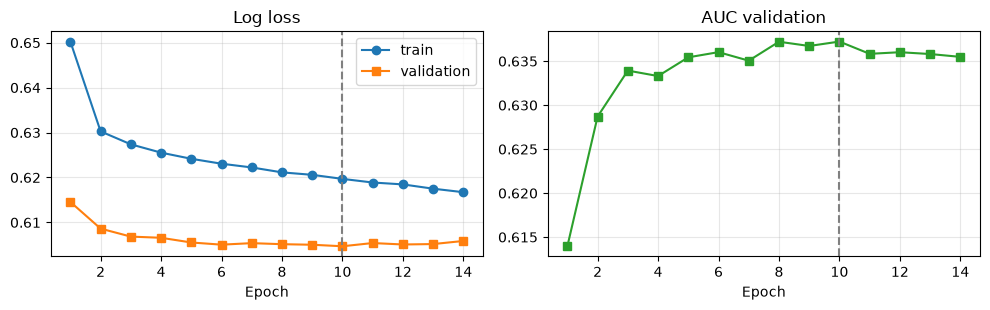

Epoch được chọn theo validation: 10 | thời gian huấn luyện gốc: 8.7 phút


In [9]:
epochs = pd.DataFrame([{'Epoch': e['epoch'], 'Loss train': e['trainConceptWeightedLoss'],
                        'Log loss validation': e['validation']['log_loss'], 'AUC validation': e['validation']['auc']}
                       for e in json.loads((art_dir / 'dkt-epochs.json').read_text())])
best_epoch = reports['dkt']['selectedEpoch']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(epochs['Epoch'], epochs['Loss train'], 'o-', label='train'); ax[0].plot(epochs['Epoch'], epochs['Log loss validation'], 's-', label='validation')
ax[1].plot(epochs['Epoch'], epochs['AUC validation'], 's-', color='tab:green')
for a, title in zip(ax, ['Log loss', 'AUC validation']):
    a.axvline(best_epoch, ls='--', c='gray'); a.set_title(title); a.set_xlabel('Epoch'); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()
print('Epoch được chọn theo validation:', best_epoch, '| thời gian huấn luyện gốc:', round(reports['dkt']['seconds'] / 60, 1), 'phút')

In [10]:
from dkt import official_dkt, make_windows, collate, evaluate
from torch.utils.data import DataLoader
torch.set_num_threads(2)
t = time.time()
checkpoint = torch.load(art_dir / 'dkt-best.pt', map_location='cpu', weights_only=True)
dkt_model = official_dkt()(len(checkpoint['concepts']), checkpoint['hidden'], dropout=.2)
dkt_model.load_state_dict(checkpoint['state'])
cfg = reports['dkt']['config']
windows = make_windows(test, tags, checkpoint['concepts'], cfg['window'], cfg['context'])
p_dkt = evaluate(dkt_model, DataLoader(windows, batch_size=32, collate_fn=collate), test)
m_dkt = metrics(test.correct, p_dkt)
print(f'SHA-256 checkpoint: {sha(art_dir / "dkt-best.pt")[:16]}…  ({time.time() - t:.0f} giây)')

SHA-256 checkpoint: bb1610f1c3c84671…  (19 giây)


## 7. Đối chiếu toàn bộ với số liệu trong báo cáo

In [11]:
reported_all = {
    'DAS3H d=0': reports['das3h_training']['metrics']['own_das3h'],
    'Log-PFA + item': reports['logistic']['models']['log_pfa_item']['test'],
    'Item-only': reports['das3h_training']['metrics']['item_only'],
    'DKT (pyKT)': reports['dkt']['metrics']['test'],
    'BKT (pyBKT)': reports['bkt']['metrics']['test'],
}
reproduced_all = {
    'DAS3H d=0': ('Huấn luyện lại', retrained['DAS3H d=0']),
    'Log-PFA + item': ('Huấn luyện lại', retrained['Log-PFA + item']),
    'Item-only': ('Huấn luyện lại', retrained['Item-only']),
    'DKT (pyKT)': ('Nạp checkpoint', m_dkt),
    'BKT (pyBKT)': ('Nạp tham số', m_bkt),
}
rows = []
for name in reported_all:
    how, r = reproduced_all[name]
    row = {'Mô hình': name, 'Cách kiểm chứng': how}
    for k, label in [('auc', 'AUC'), ('log_loss', 'Log loss'), ('brier', 'Brier')]:
        row[f'{label} báo cáo'] = round(reported_all[name][k], 4)
        row[f'{label} notebook'] = round(r[k], 4)
    row['Chênh lệch lớn nhất'] = max(abs(r[k] - reported_all[name][k]) for k in ['auc', 'log_loss', 'brier'])
    rows.append(row)
final = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
display(final)
assert (final['Chênh lệch lớn nhất'] < 1e-4).all(), 'Có số liệu không tái lập được'
print('Tất cả số liệu khớp với báo cáo đến 4 chữ số thập phân.')
print('DAS3H chấm lại từ model.json, chênh lệch:', f"{max(abs(m_das3h_reload[k] - reported[k]) for k in ['auc', 'log_loss', 'brier']):.1e}")

,Mô hình,Cách kiểm chứng,AUC báo cáo,AUC notebook,Log loss báo cáo,Log loss notebook,Brier báo cáo,Brier notebook,Chênh lệch lớn nhất
0,DAS3H d=0,Huấn luyện lại,0.7037,0.7037,0.5797,0.5797,0.1979,0.1979,1.33836e-07
1,Log-PFA + item,Huấn luyện lại,0.7023,0.7023,0.5774,0.5774,0.1971,0.1971,9.2855e-08
2,Item-only,Huấn luyện lại,0.6988,0.6988,0.589,0.589,0.2018,0.2018,1.25017e-07
3,DKT (pyKT),Nạp checkpoint,0.6083,0.6083,0.6211,0.6211,0.2154,0.2154,0
4,BKT (pyBKT),Nạp tham số,0.5952,0.5952,0.6236,0.6236,0.2166,0.2166,0


Tất cả số liệu khớp với báo cáo đến 4 chữ số thập phân.
DAS3H chấm lại từ model.json, chênh lệch: 5.2e-10


## 8. Vẽ lại Hình 4.3 từ số liệu notebook vừa tính

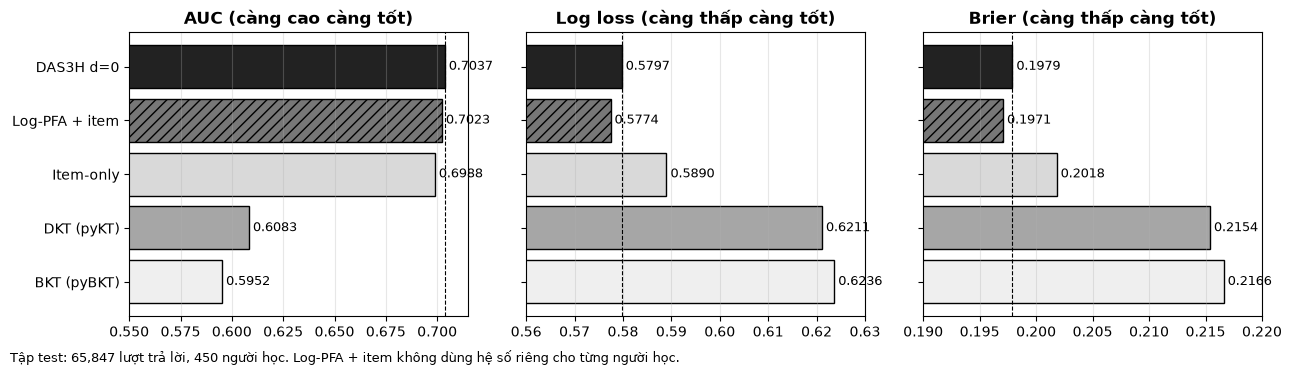

Tổng thời gian chạy notebook: 5.5 phút


In [12]:
order = ['DAS3H d=0', 'Log-PFA + item', 'Item-only', 'DKT (pyKT)', 'BKT (pyBKT)']
vals = {n: reproduced_all[n][1] for n in order}
colors = ['#222222', '#777777', '#d9d9d9', '#a6a6a6', '#efefef']
hatches = ['', '///', '', '', '']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (k, title, lim) in zip(axes, [('auc', 'AUC (càng cao càng tốt)', (.55, .715)),
                                      ('log_loss', 'Log loss (càng thấp càng tốt)', (.56, .63)),
                                      ('brier', 'Brier (càng thấp càng tốt)', (.19, .22))]):
    v = [vals[n][k] for n in order]
    bars = ax.barh(order[::-1], v[::-1], color=colors[::-1], edgecolor='black', hatch=None)
    for b, h in zip(bars, hatches[::-1]): b.set_hatch(h)
    for b, x in zip(bars, v[::-1]): ax.text(x, b.get_y() + b.get_height() / 2, f' {x:.4f}', va='center', fontsize=9)
    ax.axvline(vals['DAS3H d=0'][k], ls='--', c='black', lw=.8)
    ax.set_xlim(*lim); ax.set_title(title, fontweight='bold'); ax.grid(axis='x', alpha=.3)
fig.text(.01, -.02, f'Tập test: {len(test):,} lượt trả lời, {test.user_id.nunique()} người học. Log-PFA + item không dùng hệ số riêng cho từng người học.', fontsize=9)
plt.tight_layout(); plt.show()
print(f'Tổng thời gian chạy notebook: {(time.time() - T0) / 60:.1f} phút')

## Kết luận

* Dữ liệu dùng trong notebook trùng với dữ liệu của mọi lượt huấn luyện gốc (cùng mã băm SHA-256), cùng cách chia tập theo người học và cùng số lượt mỗi tập.
* Mô hình DAS3H đang triển khai cho đúng số liệu đã báo cáo khi chấm lại.
* Huấn luyện lại DAS3H d=0, Item-only và Log-PFA + item bằng mã nguồn gốc chọn đúng siêu tham số cũ và cho kết quả trùng đến 4 chữ số thập phân; chênh lệch rất nhỏ còn lại (cỡ 10⁻⁷) đến từ khác biệt số học giữa hai máy: lượt gốc chạy trên Windows, lượt kiểm chứng ngày 24/11/2026 chạy trên Linux với cùng phiên bản numpy, scipy, scikit-learn và pandas.
* BKT và DKT được chấm lại từ tham số/checkpoint đã chọn bằng validation; số liệu trùng với báo cáo.

**Giới hạn đã nêu trong khóa luận:** một lần chia tập (seed 42) trên một nhóm 3.000 người học; nhãn OWN là nhãn ứng viên chưa được thẩm định độc lập; BKT có 44/93 fit chạm giới hạn 40 vòng EM; DKT dùng ngân sách huấn luyện giới hạn. Kết quả cho thấy DAS3H phù hợp để triển khai trong điều kiện này, không chứng minh mọi mô hình học sâu đều kém hơn.